In [1]:
import networkx as nx

In [2]:
# Распространение доверия
# Correct abd smooth

from torch_geometric.datasets import KarateClub
import torch_geometric

/Users/dest1n/Studies/IAGN/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/dest1n/Studies/IAGN/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


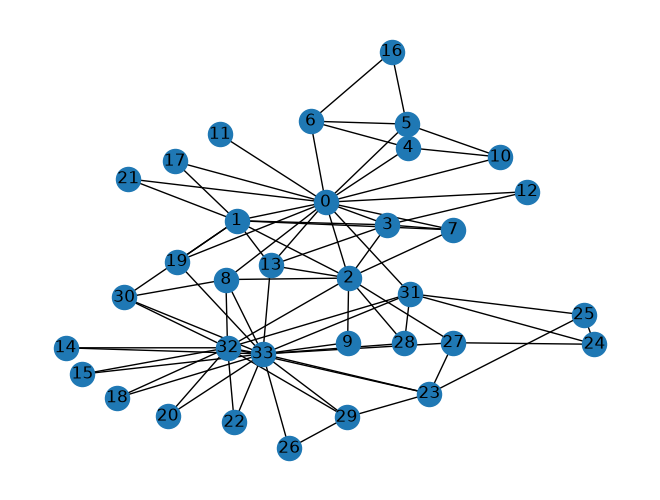

In [ ]:
dataset = KarateClub()
data = dataset[0]

g = torch_geometric.utils.to_networkx(data, to_undirected=True)
pos = nx.kamada_kawai_layout(g)
nx.draw(g, pos, with_labels=True)

Processing...
Done!


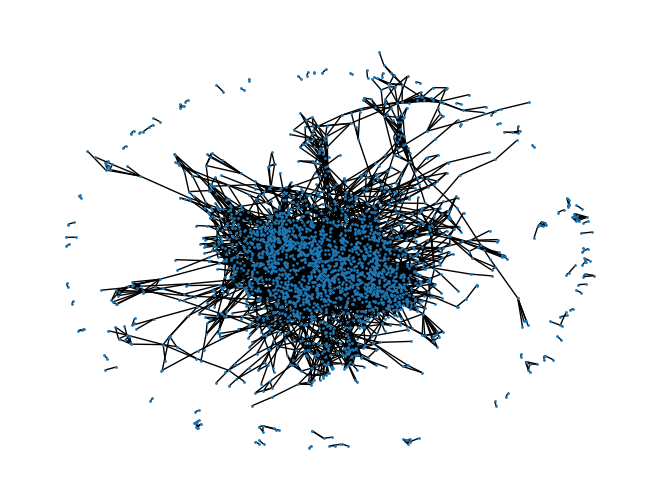

In [ ]:
from torch_geometric.datasets import Planetoid
dataset = Planetoid(root="./data", name = "Cora")
data = dataset[0]
g = torch_geometric.utils.to_networkx(data, to_undirected=True)
pos = nx.spring_layout(g)
nx.draw(g, node_size=1)

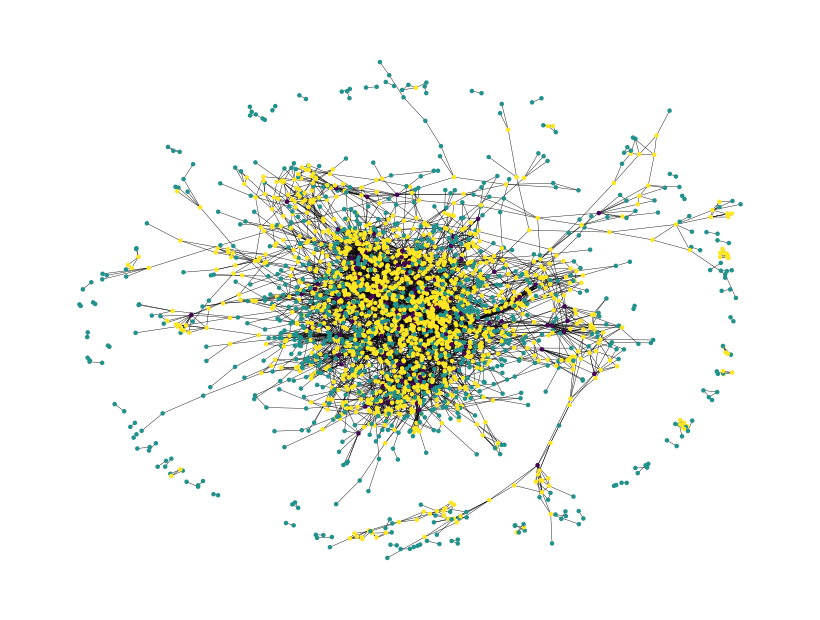

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture


deg = g.degree
deg_arr = np.array(deg)
nodes, degrees = deg_arr[:, 0], deg_arr[:, 1]

x_deg = np.log(degrees).reshape(-1, 1)
clf_deg = GaussianMixture(n_components=3)

color = clf_deg.fit_predict(x_deg)

pos = nx.spring_layout(g, seed=0)
plt.figure(figsize=(8, 6))
nx.draw(g, pos, node_size=5, node_color=color, width=0.3)

plt.show()
